### Headers

In [1]:
import os
import sys
import math
import torch
import numpy as np
import matplotlib as mp
import matplotlib.pyplot as plt
import igl
import types
from ipywidgets import interact
from collections import defaultdict
from itertools import combinations
from mpl_toolkits.mplot3d import Axes3D
from scipy.optimize import minimize
from collections import deque
import glob
import plotly.graph_objects as go
from functools import partial


workspace_path = os.path.dirname(os.path.dirname(os.path.abspath("__file__")))
print(workspace_path)
sys.path.append(workspace_path)

from lib.utils_sim import *
# from lib.utils2 import *
import meshplot as mp

device = torch.device("cuda:0")

/path/to/shape-from-heat-conduction-and-shading


### Params

In [2]:
sim_params = {
    'sim_width'  : 128,
    'sim_height' : 128,
    'obj_name' : 'spot_triangulated',#'igea-60kf', #'wineglass', #'armadillo', #'spot_triangulated', #'bunny',#'bunny-15k-r'# 'concave_wave',
    'obj_zdist': 100,
    'theta_s': 20, #30, 50 #20,
    'phi_s'  :  40, #40,
    'candidates' : 15,
    'noise' : 0.2,
    }
width  = sim_params['sim_width']
height = sim_params['sim_height']

In [3]:
params_dist = {
    'sim_img_size': (128, 128),
    'obj_name' : 'bunny-15k', #'concave-25', #'wineglass', #bunny-cut', #'bunny-15k', 'Sphere'
    'obj_zdist': 100,
    'theta_s_gt_deg': 20, # 0<theta<180 (pi)
    'phi_s_gt_deg' : 40.0, # 0<phi<360 (2pi)
}
params = types.SimpleNamespace(**params_dist)
width  = params.sim_img_size[0]
height = params.sim_img_size[1]

### Construct / Load ground truth Obj mesh

In [4]:
if sim_params['obj_name'] is not None:
    camera_mesh_name = f"{sim_params['obj_name']}_camera_{width}x{height}_{sim_params['obj_zdist']}"
    camera_mesh_path = Path(workspace_path) / f"objs/{camera_mesh_name}.obj"
    
    # if not camera_mesh_path.exists():
    verts_np, faces_np, mask_flat = construct_camera_mesh(sim_params['obj_name'], width, height, sim_params['obj_zdist'], return_mask=True)
    mask2d = mask_flat.reshape(height, width)
    
    # Load camera mesh
    verts_np, faces_np = get_vf_for_obj(camera_mesh_name, norm=False)
    
else:
    # define triangular mesh with simple geometry
    verts_np, faces_np, ii, jj = create_reg_tri_mesh_from_camera(width, height)
    verts_np[:, 2] = -(verts_np[:, 0]**2 + verts_np[:, 1]**2)
    mask = np.zeros(verts_np.shape[0])

pixel_pitch = verts_np[1, 0] - verts_np[0, 0]

# create Trimesh object
mesh = trimesh.Trimesh(vertices=verts_np, faces=faces_np)

Loaded mesh from /path/to/shape-from-heat-conduction-and-shading/objs/spot_triangulated.obj
Scaled mesh to be within coords: Min: [-0.54687627 -0.97388901 -1.        ] and Max: [0.54687627 0.9865651  0.99232252]
Constructed a camera mesh for spot_triangulated and saved it for future reuse at /path/to/shape-from-heat-conduction-and-shading/objs/spot_triangulated_camera_128x128_100.obj.
Loaded mesh from /path/to/shape-from-heat-conduction-and-shading/objs/spot_triangulated_camera_128x128_100.obj


### Get GT normal, pq

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-27.243267457088223..28.69987578399969].


gtnormals_pq_np (16384, 3)


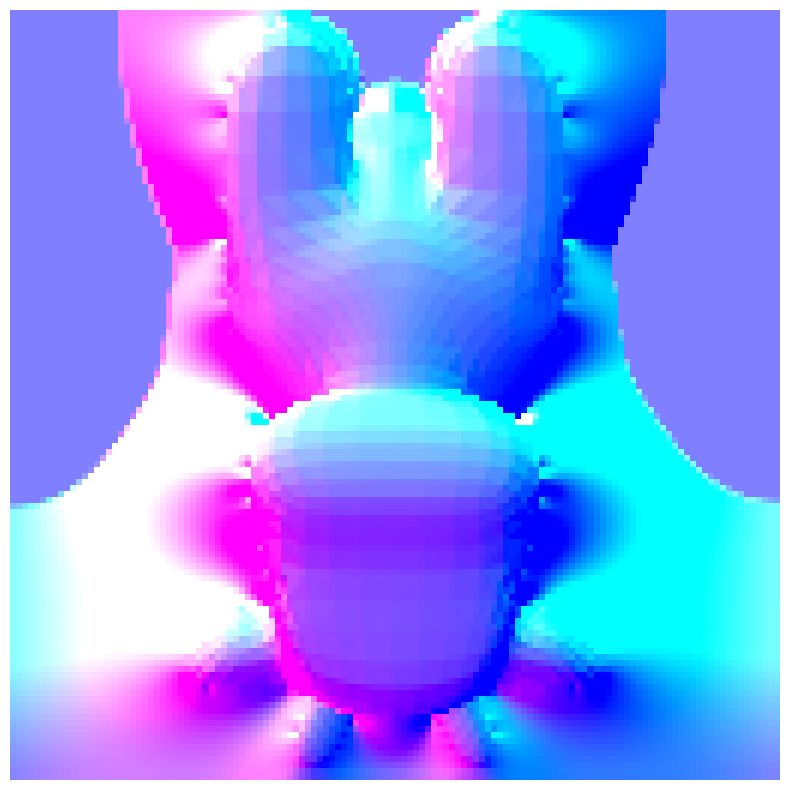

In [5]:
# Finite differencial nomals ()
gtnormals_np = compute_finite_difference_normals(verts_np, width, height, "fwd")
# Get theta, phi
nx = -gtnormals_np[..., 0]
ny = -gtnormals_np[..., 1]
nz = -gtnormals_np[..., 2]
nz_clipped = np.clip(nz, -1.0, 1.0)
theta_n = np.arccos(nz_clipped)
phi_n = np.arctan2(ny, nx)
phi_n = (phi_n + 2.0*np.pi) % (2.0*np.pi) # normalize to [0, 2*pi)
# Get p,q (normalized by nz)
gtnormals_pq_np = gtnormals_np / gtnormals_np[:, 2:3]
p_gt = gtnormals_pq_np[:, 0]
q_gt = gtnormals_pq_np[:, 1]
N = len(p_gt)
print("gtnormals_pq_np", gtnormals_pq_np.shape)

# Optional (check normal map)
normal_map = gtnormals_pq_np.reshape((height, width, 3))
normal_map = (normal_map + 1) / 2
plt.figure(figsize=(10,10))
plt.imshow(normal_map)
plt.axis("off")
plt.show()

sx_gt 0.2620026302293849
sy_gt 0.21984631039295416
sz_gt 0.9396926207859084
ps_gt 0.2788173754203369
qs_gt 0.23395555688102193
s_gt [ 0.27881738  0.23395556 -1.        ] (3,)
eta_est_1d (16384,)
eta_gt (128, 128)


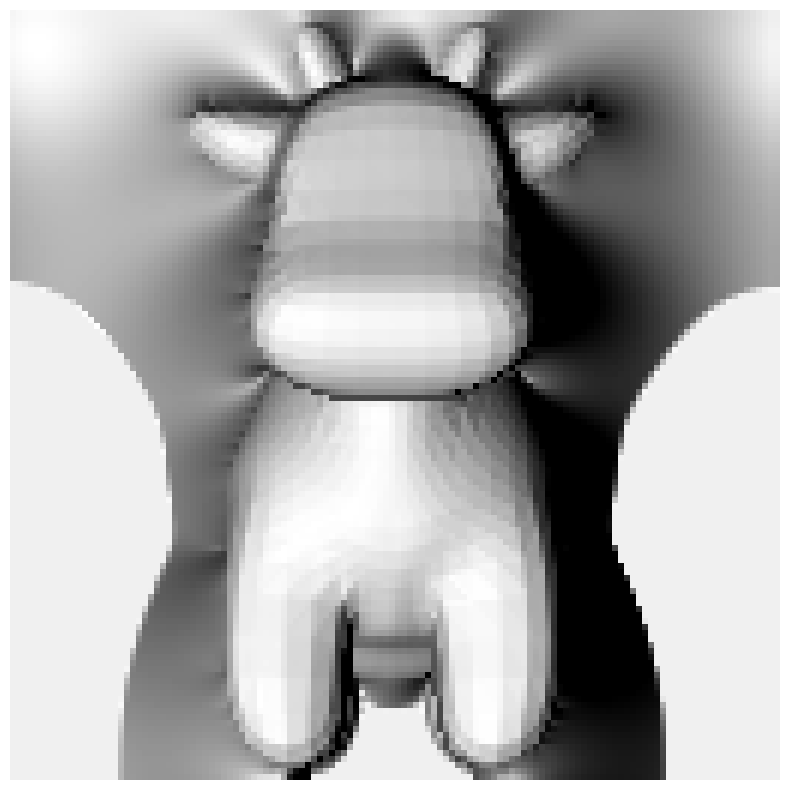

In [6]:
# Prepare known variables (Estimated eta, s)
# Set Spherical coords. (theta, phi)
theta_s_gt = np.deg2rad(params.theta_s_gt_deg)
phi_s_gt   = np.deg2rad(params.phi_s_gt_deg)
sx_gt = math.sin(theta_s_gt) * math.cos(phi_s_gt)
sy_gt = math.sin(theta_s_gt) * math.sin(phi_s_gt)
sz_gt = math.cos(theta_s_gt)
ps_gt = sx_gt / sz_gt
qs_gt = sy_gt / sz_gt
s_gt = np.array([ps_gt, qs_gt, -1.0], dtype=float)

# Shading Eq. (p,q)
def compute_shading_value(p, q, ps, qs):
    denom_n = np.sqrt(p**2 + q**2 + 1.0)
    denom_s = np.sqrt(ps**2 + qs**2 + 1.0)
    shading = (p*ps + q*qs + 1.0) / (denom_n * denom_s)
    shading = np.maximum(shading, 0.0)
    return shading
eta_est_1d = compute_shading_value(p_gt, q_gt, ps_gt, qs_gt)
eta_gt = eta_est_1d.reshape((height, width))

# Shading Eq. (Spherical coords.)
eta_est_1d_phi_theta = (np.sin(theta_n)*np.sin(theta_s_gt)*np.cos(phi_n - phi_s_gt) + np.cos(theta_n)*np.cos(theta_s_gt))
eta_est_1d_phi_theta = np.maximum(eta_est_1d_phi_theta, 0.0)
eta_gt_phi_theta = eta_est_1d_phi_theta.reshape((height, width))

print("sx_gt", sx_gt)
print("sy_gt", sy_gt)
print("sz_gt", sz_gt)
print("ps_gt", ps_gt)
print("qs_gt", qs_gt)

print("s_gt", s_gt, s_gt.shape)
print("eta_est_1d", eta_est_1d.shape)
print("eta_gt", eta_gt.shape)

plt.figure(figsize=(10, 10))
plt.imshow(eta_gt, cmap='gray', origin='lower')
plt.axis("off")
#plt.savefig("eta_gt_high_res.png", dpi=300, bbox_inches='tight')  # Save with high resolution
plt.show()

assert np.allclose(eta_gt, eta_gt_phi_theta, atol=1e-5)

### Set Source Direction and Shading

### Verify equation for cotan laplacians

In [7]:
ind_v, ind_a, ind_b, ind_c, ind_d, ind_e, ind_f, ind_g, ind_h = get_ngbr_indices(width, height)


### Get GT $\Delta$ from GT verts and faces

In [8]:
# Using the default regular 6 connectivity to compute laplacian
ngbr_inds = np.vstack((ind_a, ind_b, ind_c, ind_d, ind_e, ind_f)).T.reshape(-1)
ver_inds = np.repeat(ind_v, 6)
gtlaplacian_default_np = igl.cotmatrix(verts_np, faces_np).toarray()[ver_inds, ngbr_inds].reshape(-1, 6)

print("gtlaplacian_default_np", gtlaplacian_default_np.shape)

gtlaplacian_default_np (15876, 6)


### Get cotan $\tilde{\Delta}$ from GT normal (and compare to GT $\Delta$)

In [9]:
vertex_cotan_laplacians = cotan_laplacians_from_pq_np(gtnormals_pq_np, width, height)
assert np.all(np.isclose(gtlaplacian_default_np, vertex_cotan_laplacians, atol=1e-5))

## Estimate Light Source Direction

INPUT: GT laplacian and shading
- Find wij where locally same
- Planar initialization
- Estimate ps, qs (RANSAC approach) => There may have two solutions(ps,qs)(-ps,-qs)
- set initial ps, qs

### Find flat region where wi0,j1=wi0,j4, wi0,j2=wi0,j5, wi0,j3=wi0,6

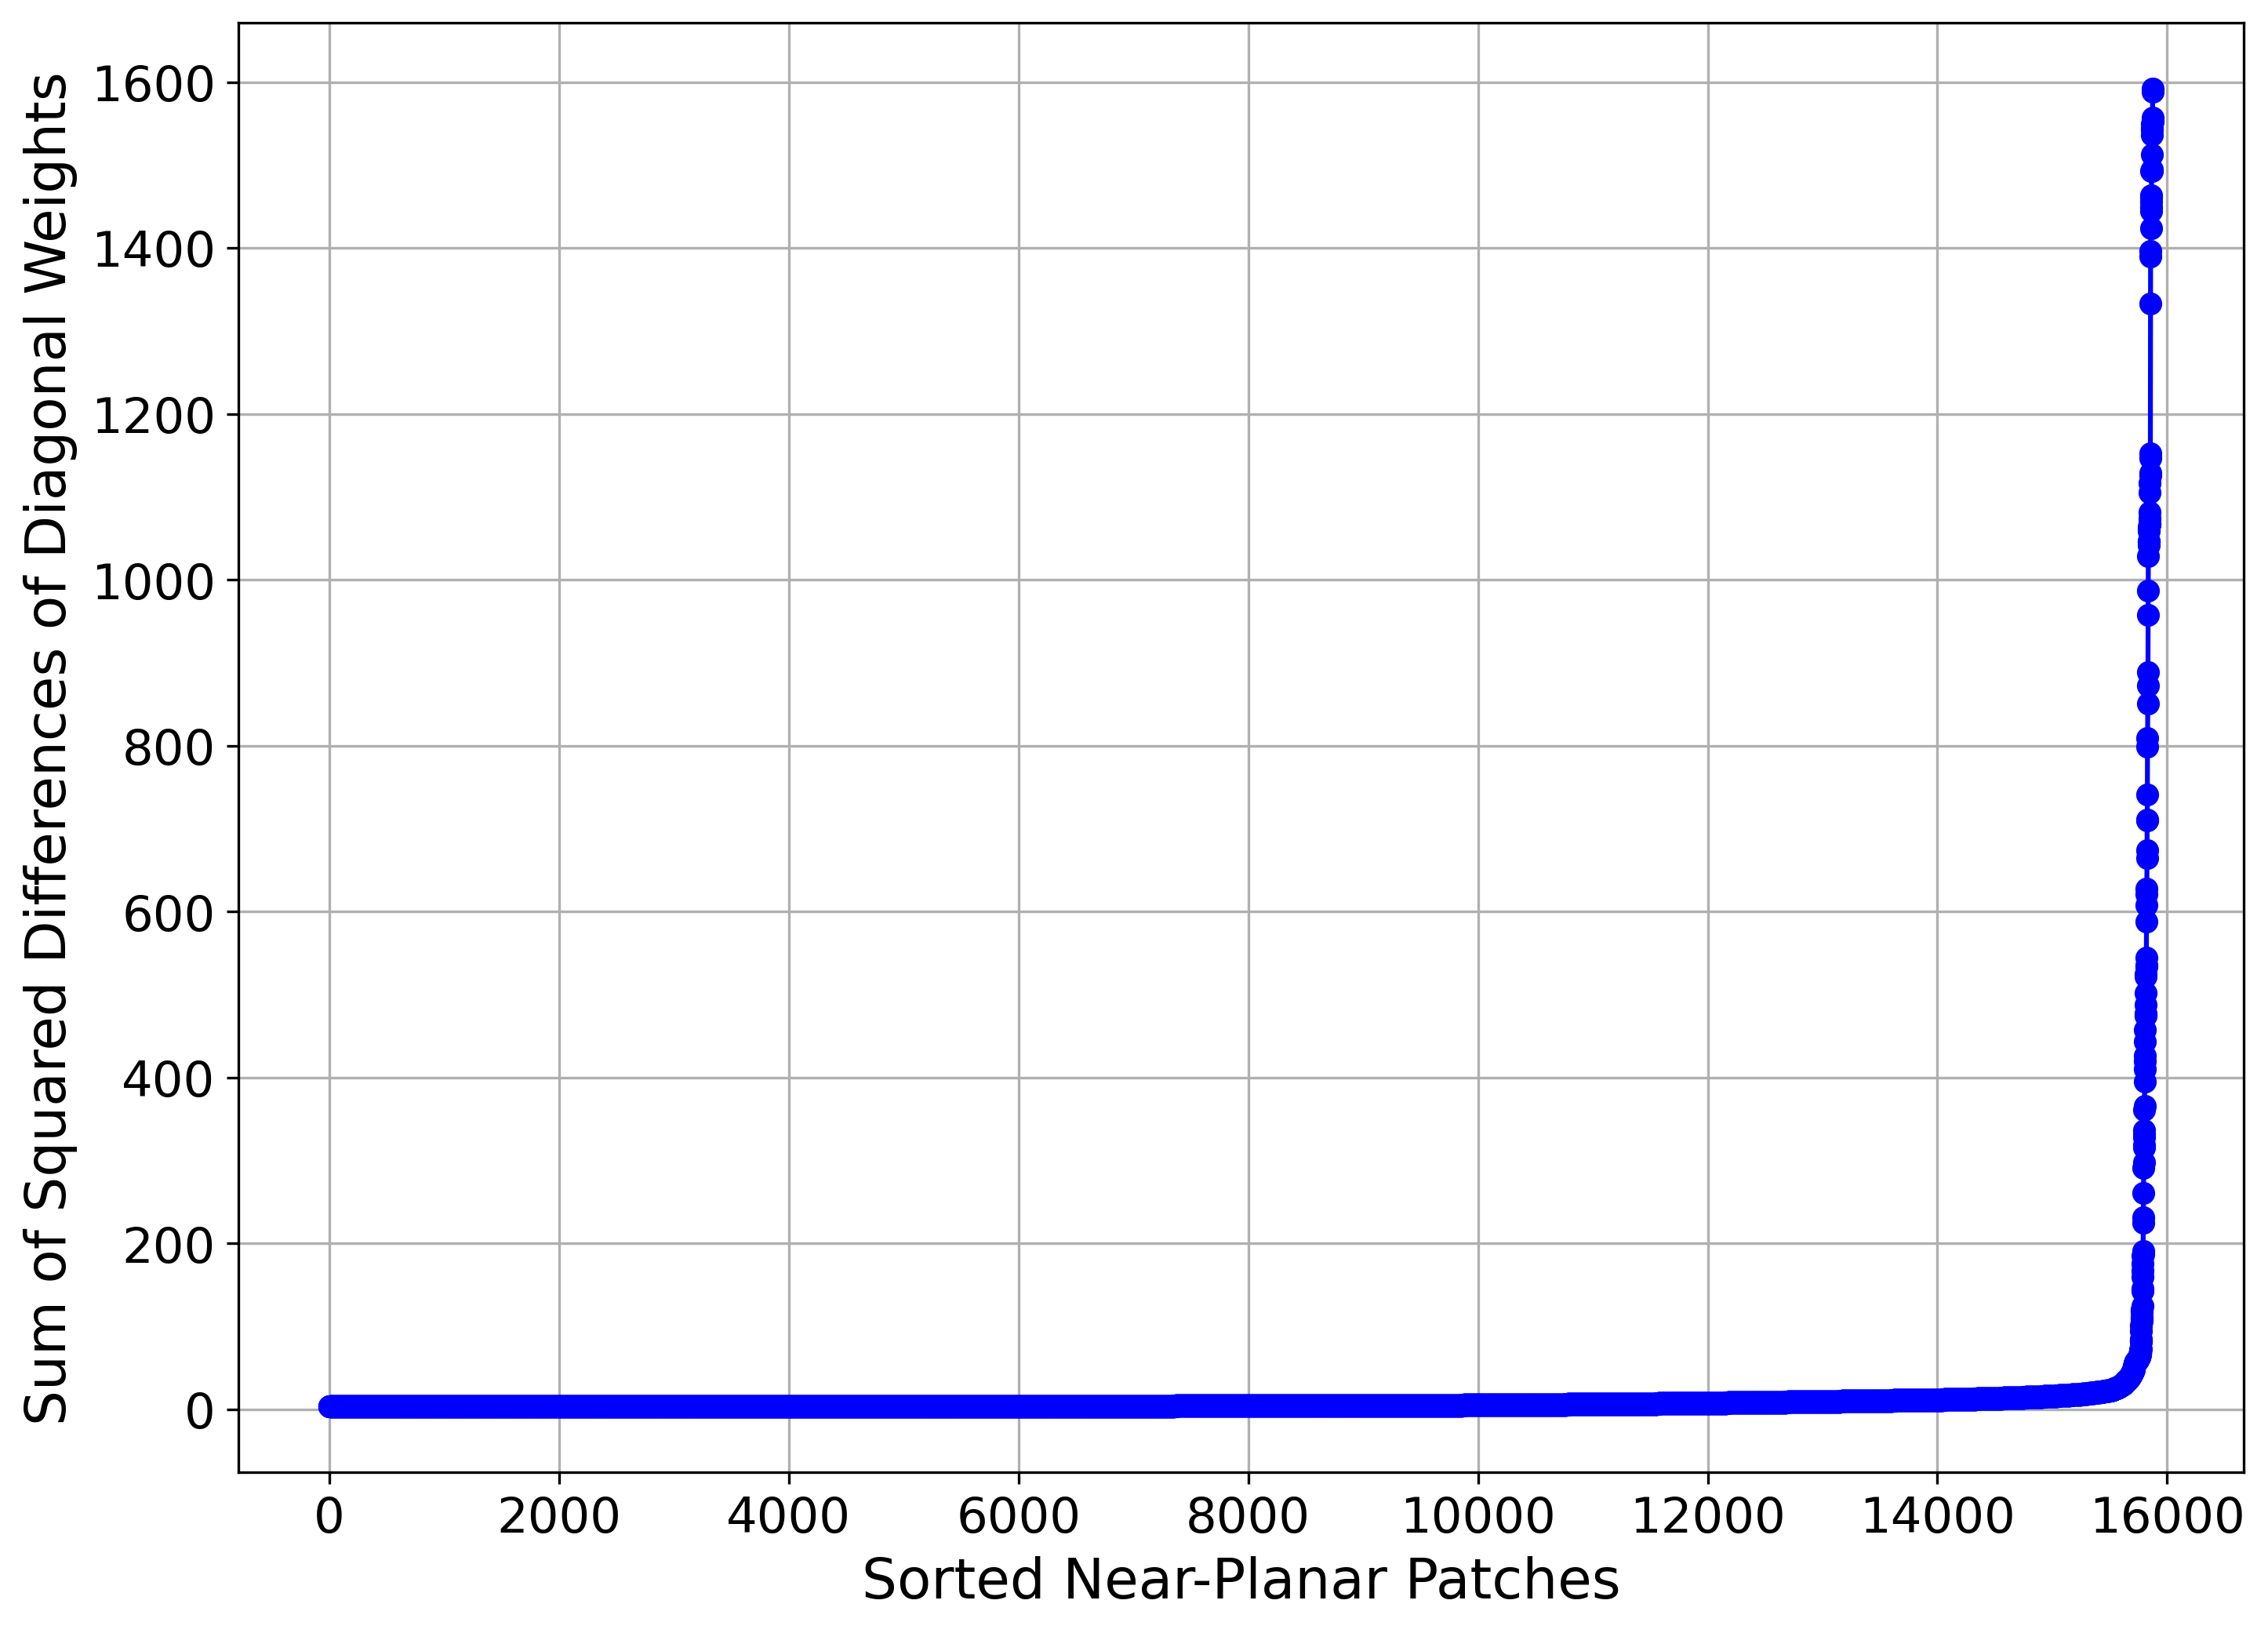

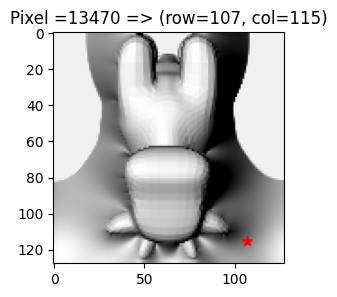

In [10]:
import matplotlib as mpl

def find_flat_regions(gtlaplacian_default_np, alpha=None, N_CANDIDATES=None):
    n = len(gtlaplacian_default_np)
    if N_CANDIDATES is None:
        N_CANDIDATES = n

    # Find flat region
    norm_l2 = np.linalg.norm(gtlaplacian_default_np, axis=1)
    nonzero_mask = norm_l2 > 1e-12
    data_nonzero = gtlaplacian_default_np[nonzero_mask]
    indices_nonzero = np.where(nonzero_mask)[0]

    diff_wij14 = (data_nonzero[:, 0] - data_nonzero[:, 3])**2  # (wi0j1 - wi0j4)^2
    diff_wij25 = (data_nonzero[:, 1] - data_nonzero[:, 4])**2  # (wi0j2 - wi0j5)^2
    diff_wij36 = (data_nonzero[:, 2] - data_nonzero[:, 5])**2  # (wi0j3 - wi0j6)^2
    sum_diff = diff_wij14 + diff_wij25 + diff_wij36
    sum_abs = np.sum(np.abs(data_nonzero), axis=1)

    metric = sum_diff + alpha * sum_abs

    # Sort
    sorted_idx_local = np.argsort(metric)
    sorted_idx_global = indices_nonzero[sorted_idx_local]

    # Top N_CANDIDATES
    top_indices = sorted_idx_global[:N_CANDIDATES]
    all_sorted_global_idx  = sorted_idx_global
    all_sorted_values      = data_nonzero[sorted_idx_local]

    sorted_metric = metric[sorted_idx_local]
    
    
    mpl.rcParams["mathtext.fontset"] = "cm"
    plt.figure(figsize=(11, 8), dpi=300)
    plt.plot(sorted_metric, marker='o', linestyle='-', color='b')
    plt.ylabel("Sum of Squared Differences of Diagonal Weights", fontsize=17)
    plt.xlabel("Sorted Near-Planar Patches", fontsize=17)

    plt.xticks(fontsize=15)
    plt.yticks(fontsize=15)
    plt.grid(True)
    plt.show()

    return all_sorted_global_idx, all_sorted_values, top_indices

all_sorted_global_idx, all_sorted_values, top_indices = find_flat_regions(gtlaplacian_default_np, alpha=1.0, N_CANDIDATES=None)

# Visualize
i = all_sorted_global_idx[0]
row_idx = (i // 126) + 1
col_idx = (i %  126) + 1
plt.figure(figsize=(3,3))
plt.scatter(row_idx, col_idx, color="red", marker="*", s=50, label="Target Pixel")
plt.title(f"Pixel ={i} => (row={row_idx}, col={col_idx})")
plt.imshow(eta_gt, cmap='gray')
plt.show()

### Planar initialization

In [11]:
def compute_x0_from_w(w, x0_prev):
    A = (w[0] + w[3]) / 2.0
    B = (w[1] + w[4]) / 2.0
    C = (w[2] + w[5]) / 2.0

    if np.abs(C) == 0:
        # either p or q must be zero. 
        # assert A**2 - 1 >= 0 and B**2 - 1 >= 0
        if A**2 - 1 >= 0 and B**2 - 1 >= 0:
            p = np.sqrt(A**2 - 1)
            q = np.sqrt(B**2 - 1)
            # cannot recover scale when C = 0
            scale = np.nan
        else:
            p = 0
            q = 0
            scale = 1
    else:
        L = (A-B)/C
        
        x1 = (L + np.sqrt(L**2 + 4)) / 2
        x2 = (L - np.sqrt(L**2 + 4)) / 2

        solns = []
        if x1 / (x1 + 1 + B/C) <= 0:
            q = np.sqrt(-x1/(x1+1+B/C))
            p = q / x1
            solns.append((p, q))
        
        if x2 / (x2 + 1 + B/C) <= 0:
            q = np.sqrt(-x2/(x2+1+B/C))
            p = q / x2
            solns.append((p, q))

        if len(solns) > 1:
            print(f"Found multiple solutions: {len(solns)}")
        elif len(solns) == 0:
            x0 = np.random.uniform(-1, 1, 8)
            scale = 1 # np.nan
            return x0, scale
            # raise RuntimeError(f"Did not find any valid initializations for weights {w}")
        
        p, q = solns[0]

        scale_A = A / ((p * (p+q) + 1) / np.sqrt(1 + p**2 + q**2))
        scale_B = B / ((q * (p+q) + 1) / np.sqrt(1 + p**2 + q**2))
        scale = 0.5 * (scale_A + scale_B)
    
    x0_new = np.array([p, q, q, p, p, q, q, p]) 

    # check if sign must be flipped
    max_val_pos = np.abs(x0_prev).argmax()
    if np.sign(x0_prev[max_val_pos]) * np.sign(x0_new[max_val_pos]) < 0:
        x0_new = -x0_new

    x0 = x0_prev.copy()
    x0[x0_prev == 0] = x0_new[x0_prev == 0]

    return x0, scale

def extract_candidates(all_sorted_global_idx, all_sorted_values, TOP_K=None):
    x0_prev = np.zeros(8, dtype=float)
    candidates = []
    count = min(TOP_K, len(all_sorted_global_idx))

    for rank in range(count):
        pix_id = all_sorted_global_idx[rank]
        w_vals = all_sorted_values[rank]

        x0, scale = compute_x0_from_w(w_vals, x0_prev)
        p = x0[4]
        q = x0[5]
        
        candidates.append((pix_id, p, q, p, q, p, q, scale))
    return candidates

all_candidates = extract_candidates(all_sorted_global_idx, all_sorted_values, TOP_K=30)
print("Example", all_candidates[0])

Example (13470, -0.9682303059960938, 0.9809564487858323, -0.9682303059960938, 0.9809564487858323, -0.9682303059960938, 0.9809564487858323, 1.001020299890628)


### Initial source direction estimation

In [12]:
pq_list = []
eta_list = []

N = len(all_candidates)
for (pix_id, p, q, p, q, p, q, scale) in all_candidates:
    row_idx = (pix_id // 126) + 1
    col_idx = (pix_id %  126) + 1
    
    eta_val = eta_gt[row_idx, col_idx]
    pq_list.append([p, q])
    eta_list.append(eta_val)

pq_array = np.array(pq_list, dtype=np.float64)   # shape (N,2)
eta_array = np.array(eta_list, dtype=np.float64) # shape (N,)

In [13]:
def shading_slope(p, q, ps, qs, sign):
    denom_n = np.sqrt(p**2 + q**2 + 1.0)
    denom_s = np.sqrt(ps**2 + qs**2 + 1.0)
    return sign * ((p*ps + q*qs + 1.0) / (denom_n * denom_s))

def pixel_residual(p, q, ps, qs, eta_i):
    val_plus  = shading_slope(p, q, ps, qs, +1)
    val_minus = shading_slope(p, q, ps, qs, -1)

    err_plus  = abs(val_plus  - eta_i)
    err_minus = abs(val_minus - eta_i)
    if err_plus <= err_minus:
        return err_plus,  +1
    else:
        return err_minus, -1

# Non-linear cost function
def cost_function_nonlin(x, pq_array, eta_array):
    ps, qs = x
    N = len(eta_array)
    # L1 Error
    residual_sum = 0.0
    for i in range(N):
        p_i, q_i = pq_array[i]
        eta_i = eta_array[i]
        err_i, _ = pixel_residual(p_i, q_i, ps, qs, eta_i)
        residual_sum += err_i
    return residual_sum

def source_dir_est_nonlin(pq_array, eta_array, ps_init, qs_init):
    x0 = np.array([ps_init, qs_init], dtype=np.float64)
    res = minimize(fun=cost_function_nonlin,
                   x0=x0,
                   args=(pq_array, eta_array),
                   method='BFGS',
                   options={'maxiter':10, 'gtol':1e-6, 'disp':False})
    ps_est, qs_est = res.x
    # Final sign list
    N = len(pq_array)
    sign_list = np.zeros(N, dtype=int)
    for i in range(N):
        p_i, q_i = pq_array[i]
        eta_i = eta_array[i]
        _, sgn = pixel_residual(p_i, q_i, ps_est, qs_est, eta_i)
        sign_list[i] = sgn
    return ps_est, qs_est, sign_list

# RNASAC
def ransac_source_dir_est_nonlin(pq_array, eta_array,
                                 subset_size=None,
                                 n_iter=None,
                                 threshold=None,
                                 verbose=False):
    N = len(pq_array)
    if subset_size > N:
        raise ValueError("Not enough data points for subset")

    best_inlier_count = -1
    best_ps, best_qs = 0.0, 0.0
    best_sign_list = None

    for it in range(n_iter):
        # Get subset
        subset_idx = np.random.choice(N, subset_size, replace=False)
        sub_pq = pq_array[subset_idx]
        sub_eta= eta_array[subset_idx]

        # Random initialize
        while True:
            ps_init = np.random.uniform(-1.0,1.0)
            qs_init = np.random.uniform(-1.0,1.0)
            if ps_init**2 + qs_init**2 <= 1.0:
                break

        # Estimate subset
        ps_sub, qs_sub, sign_sub = source_dir_est_nonlin(sub_pq, sub_eta, ps_init, qs_init)
        # Estimate all again
        ps_all, qs_all, sign_all = source_dir_est_nonlin(pq_array, eta_array, ps_sub, qs_sub)

        # Residuals and Inlier check
        val_all = np.zeros(N, dtype=np.float64)
        for i in range(N):
            p_i, q_i = pq_array[i]
            # sign_all[i] +1/-1
            val_all[i] = shading_slope(p_i, q_i, ps_all, qs_all, sign_all[i])
        residuals = np.abs(val_all - eta_array)
        inliers = (residuals < threshold)
        inlier_count = np.sum(inliers)

        # Update best
        if inlier_count > best_inlier_count:
            best_inlier_count = inlier_count
            best_ps, best_qs = ps_all, qs_all
            best_sign_list = sign_all


    return best_ps, best_qs, best_sign_list

# --------- Ran estimation (RANSAC) --------- #
ps_est, qs_est, sign_list_ransac = ransac_source_dir_est_nonlin(pq_array, eta_array,
                                                                subset_size=20,
                                                                n_iter=30,
                                                                threshold=0.1,
                                                                verbose=True)

print(f"Initial estimated ps, qs = {ps_est:.4f}, {qs_est:.4f}")
print(f"Ground truth      ps, qs = {ps_gt:.4f}, {qs_gt:.4f}")

# If you need sign updated all_candidates, run here
all_candidates_sign_fixed = []

for i, (pix_id, p_orig, q_orig, p_orig, q_orig, p_orig, q_orig, scale) in enumerate(all_candidates):
    if sign_list_ransac[i] == -1:
        p_fixed = -p_orig
        q_fixed = -q_orig
    else:
        p_fixed = p_orig
        q_fixed = q_orig
    all_candidates_sign_fixed.append((pix_id, p_fixed, q_fixed, p_fixed, q_fixed, p_fixed, q_fixed, p_fixed, q_fixed))

Initial estimated ps, qs = 0.2587, 0.2375
Ground truth      ps, qs = 0.2788, 0.2340


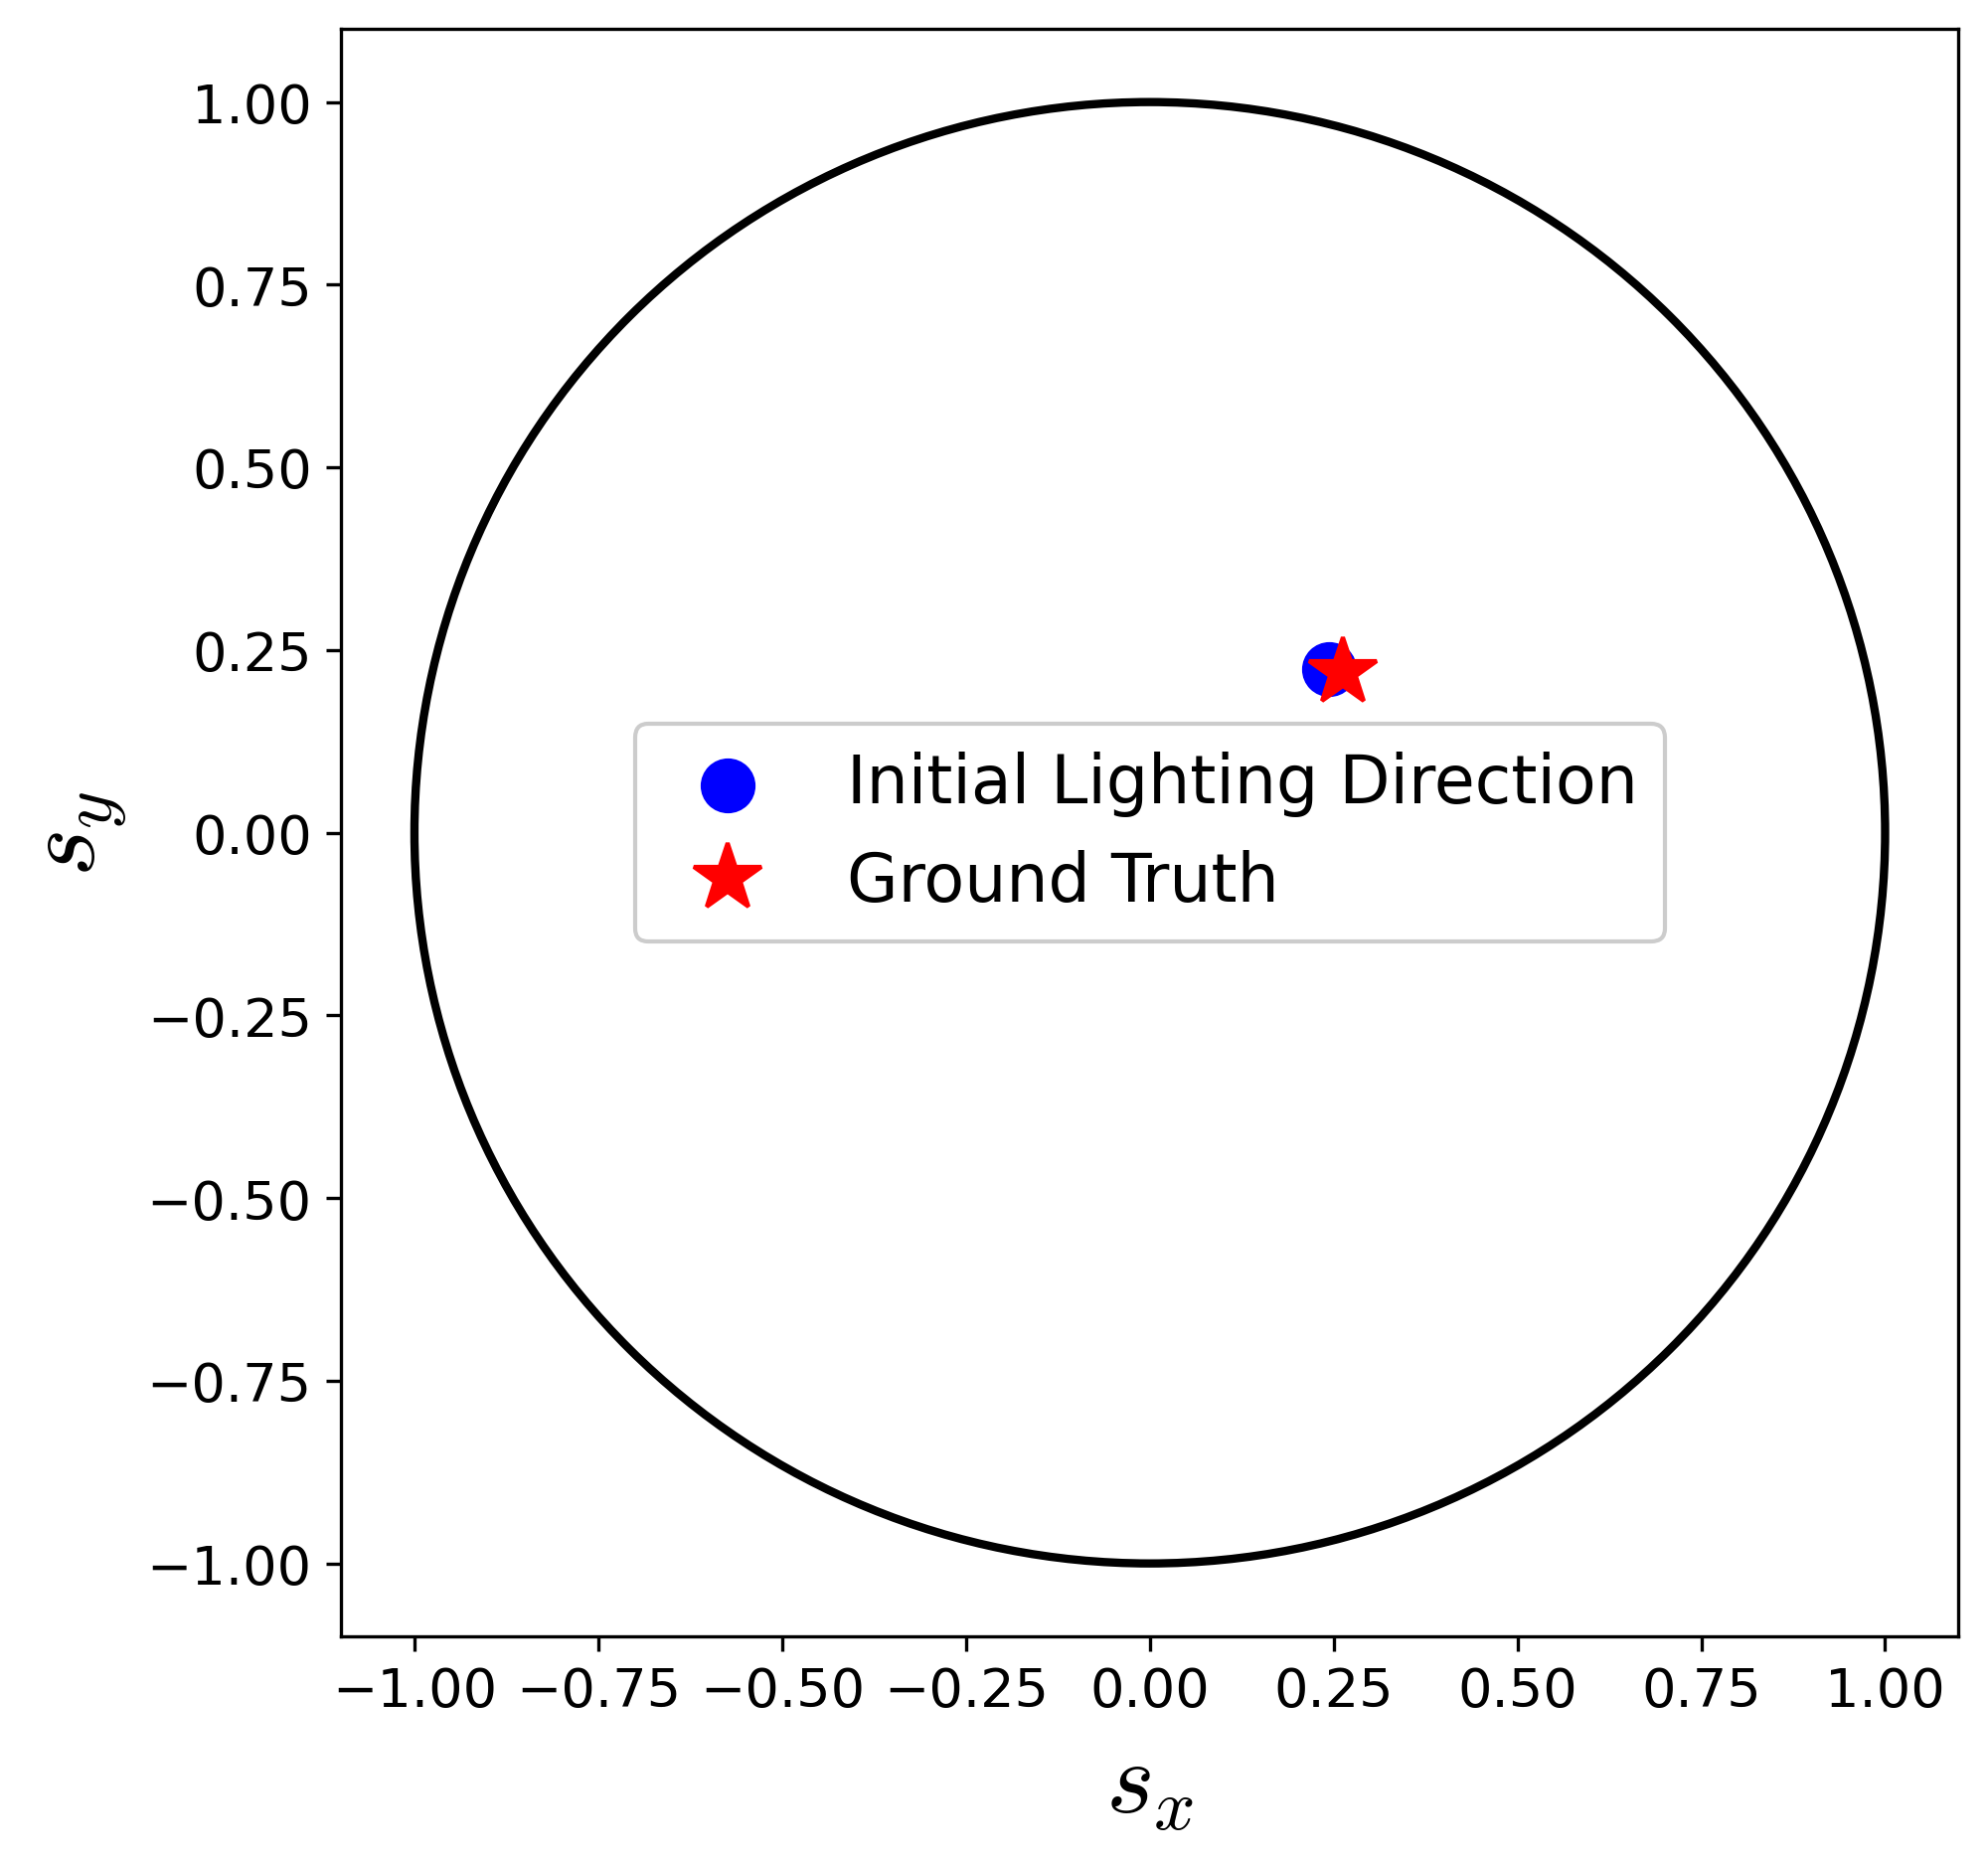

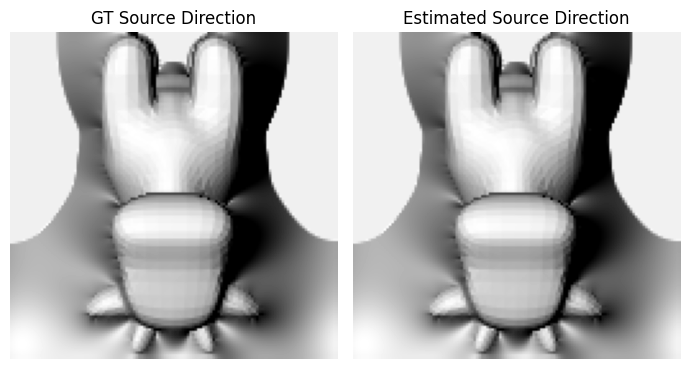

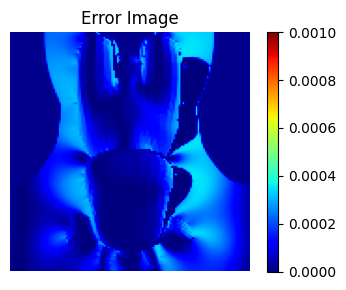

In [14]:
def pq_to_unit_vector(ps, qs):
    norm = np.sqrt(ps**2 + qs**2 + 1)
    sx = ps / norm
    sy = qs / norm
    sz = 1.0 / norm
    return sx, sy, sz

# Convert ground truth and estimated values to unit vectors
sx_gt, sy_gt, sz_gt = pq_to_unit_vector(ps_gt, qs_gt)
sx_est, sy_est, sz_est = pq_to_unit_vector(ps_est, qs_est)

marker_size = 17
scatter_marker_size = 150
plt.figure(figsize=(7,7), dpi=300)
plt.scatter(sx_est, sy_est, s=scatter_marker_size, color='blue', label='Initial Lighting Direction')
plt.plot(sx_gt, sy_gt, marker='*', markersize=marker_size, color='red', linestyle='None', label='Ground Truth')

circle = plt.Circle((0, 0), 1.0, fill=False, color='black', linewidth=2)
plt.gca().add_patch(circle)

plt.xlim([-1.1, 1.1])
plt.ylim([-1.1, 1.1])
plt.xlabel(r"$s_x$", fontsize=25)
plt.ylabel(r"$s_y$", fontsize=25)
plt.xticks(fontsize=13)
plt.yticks(fontsize=13)
#plt.title("Initial Estimated Lighting Direction", fontsize=18)
plt.legend(fontsize=16, framealpha=1.0)
plt.show()



# Shading image
eta_est_1d_est = compute_shading_value(p_gt, q_gt, ps_est, qs_est)
eta_est = eta_est_1d_est.reshape((height, width))
error_image = (eta_gt - eta_est)**2

plt.figure(figsize=(7,5))
plt.subplot(1,2,1)
plt.title("GT Source Direction")
plt.imshow(eta_gt, cmap='gray')
plt.axis("off")
plt.subplot(1,2,2)
plt.title("Estimated Source Direction")
plt.imshow(eta_est, cmap='gray')
plt.axis("off")
plt.tight_layout()
plt.show()

plt.figure(figsize=(4,3))
plt.title("Error Image")
plt.imshow(error_image, cmap='jet', vmin=0, vmax=0.001)
plt.axis("off")
plt.colorbar()
plt.tight_layout()
plt.show()

## Refine ps,qs and p,q

### Set Cost function

$$L = \left\| \Delta_{\text{gt}} - {\hat{\Delta}} \right\|_2 + \left\| \eta_{\text{gt}} - {\hat{\eta}} \right\|_2$$

In [15]:
def lap_error(x,
              idx_target, idx_a, idx_b, idx_d, idx_e, idx_f,
              i_v,
              gtlaplacian_default_np,
              width, height):
    
    p, q, p_a, q_a, p_b, q_b, p_f, q_f = x
    p_d = p + q_b - q
    p_e = p_f + q_a - q_f

    # Laplacian error
    pq_modified = np.zeros((height*width, 2), dtype=np.float64)
    pq_modified[idx_target, 0] = p
    pq_modified[idx_target, 1] = q
    pq_modified[idx_a, 1]      = q_a # a
    pq_modified[idx_b, 1]      = q_b # b
    pq_modified[idx_d, 0]      = p_d # d
    pq_modified[idx_e, 0]      = p_e # e
    pq_modified[idx_f, 0]      = p_f # f
    pq_modified[idx_f, 1]      = q_f # f
    
    lap_hat = cotan_laplacians_from_pq_np(pq_modified, width, height)
    diff_lap = gtlaplacian_default_np[i_v] - lap_hat[i_v]
    E_lap = np.mean(diff_lap**2)

    return E_lap

def shading_error(x,
                  idx_target, idx_a, idx_b, idx_f,
                  eta_est_1d,
                  ps_est, qs_est):

    p, q, p_a, q_a, p_b, q_b, p_f, q_f = x

    E_sha = 0.0

    # Only 4 neighbors are enough
    eta_center = eta_est_1d[idx_target]
    shading_val = compute_shading_value(p, q, ps_est, qs_est)
    E_sha += (shading_val - eta_center)**2

    eta_a = eta_est_1d[idx_a]
    shading_val = compute_shading_value(p_a, q_a, ps_est, qs_est)
    E_sha += (shading_val - eta_a)**2

    eta_b = eta_est_1d[idx_b]
    shading_val = compute_shading_value(p_b, q_b, ps_est, qs_est)
    E_sha += (shading_val - eta_b)**2

    eta_f = eta_est_1d[idx_f]
    shading_val = compute_shading_value(p_f, q_f, ps_est, qs_est)
    E_sha += (shading_val - eta_f)**2    

    return E_sha

def obj_function(x,
                 idx_target, idx_a, idx_b, idx_d, idx_e, idx_f,
                 i_v,
                 gtlaplacian_default_np,
                 width, height,
                 eta_est_1d,
                 ps_est, qs_est,
                 w_lap=None,
                 w_sha=None):
    
    E_lap = lap_error(x,
                      idx_target, idx_a, idx_b, idx_d, idx_e, idx_f,
                      i_v,
                      gtlaplacian_default_np,
                      width, height)

    E_sha = shading_error(x,
                          idx_target, idx_a, idx_b, idx_f,
                          eta_est_1d,
                          ps_est, qs_est)

    return w_lap * E_lap + w_sha * E_sha

In [16]:
def refine_pixel_with_optimization(idx_target,
                                   i_v,
                                   idx_a, idx_b, idx_d, idx_e, idx_f,
                                   p_init, q_init,
                                   p_a_init, q_a_init, # a
                                   p_b_init, q_b_init, # b
                                   p_f_init, q_f_init, # f
                                   gtlaplacian_default_np,
                                   width, height,
                                   ps_est, qs_est,
                                   w_lap=None,
                                   w_sha=None):
    
    x0 = np.array([p_init,   q_init,
                   p_a_init, q_a_init,
                   p_b_init, q_b_init,
                   p_f_init, q_f_init], dtype=np.float64)
    
    def wrapped_objective(x):
        return obj_function(x,
                            idx_target, idx_a, idx_b, idx_d, idx_e, idx_f,
                            i_v,
                            gtlaplacian_default_np,
                            width, height,
                            eta_est_1d,
                            ps_est, qs_est,
                            w_lap=w_lap,
                            w_sha=w_sha)
    
    res = minimize(wrapped_objective,
                   x0,
                   method="L-BFGS-B",
                   options={"ftol": 1e-12})
    best_x = res.x
    refined_result = {"p"  : best_x[0],
                      "q"  : best_x[1],
                      "p_a": best_x[2],
                      "q_a": best_x[3],
                      "p_b": best_x[4],
                      "q_b": best_x[5],
                      "p_f": best_x[6],
                      "q_f": best_x[7]}
    return refined_result

In [17]:
def run_refinement(all_candidates,
                   gtlaplacian_default_np,
                   width, height,
                   ind_v, ind_a, ind_b, ind_d, ind_e, ind_f,
                   ps_est, qs_est,
                   local_params,
                   w_lap=None,
                   w_sha=None):
    
    results_refined = []

    for i, candidate in enumerate(all_candidates):
        pix_id_init = candidate[0]
        p_init      = candidate[1]
        q_init      = candidate[2]
        p_a_init    = candidate[3]
        q_a_init    = candidate[4]
        p_b_init    = candidate[5]
        q_b_init    = candidate[6]
        p_f_init    = candidate[7]
        q_f_init    = candidate[8]

        row = (pix_id_init // 126) + 1
        col = (pix_id_init %  126) + 1
        idx_target = np.ravel_multi_index((row, col), dims=(height, width))

        i_v = np.where(ind_v == idx_target)[0][0]
        idx_a = ind_a[i_v]
        idx_b = ind_b[i_v]
        idx_d = ind_d[i_v]
        idx_e = ind_e[i_v]
        idx_f = ind_f[i_v]

        if pix_id_init in local_params:
            p_a_init, q_a_init, p_b_init, q_b_init, p_f_init, q_f_init = local_params[pix_id_init]

        refined_result = refine_pixel_with_optimization(idx_target,
                                                        i_v,
                                                        idx_a, idx_b, idx_d, idx_e, idx_f,
                                                        p_init,   q_init,
                                                        p_a_init, q_a_init, # a
                                                        p_b_init, q_b_init, # b
                                                        p_f_init, q_f_init, # f
                                                        gtlaplacian_default_np,
                                                        width, height,
                                                        ps_est, qs_est,
                                                        w_lap=w_lap,
                                                        w_sha=w_sha)
        
        p_refined = refined_result["p"]
        q_refined = refined_result["q"]
        p_a_ref = refined_result["p_a"]
        q_a_ref = refined_result["q_a"]
        p_b_ref = refined_result["p_b"]
        q_b_ref = refined_result["q_b"]
        p_f_ref = refined_result["p_f"]
        q_f_ref = refined_result["q_f"]

        local_params[pix_id_init] = (p_a_ref, q_a_ref, p_b_ref, q_b_ref, p_f_ref, q_f_ref)

        results_refined.append((pix_id_init, p_refined, q_refined, p_a_ref, q_a_ref, p_b_ref, q_b_ref, p_f_ref, q_f_ref))

    return results_refined

In [18]:
def run_source_estimation(all_candidates,
                          eta_gt,
                          ransac_source_dir_est_nonlin,
                          subset_size=None,
                          n_iter=None,
                          threshold=None,
                          verbose=True):
    
    pq_list = []
    eta_list = []

    N = len(all_candidates)
    for (pix_id, p, q, p_a, q_a, p_b, q_b, p_f, q_f) in all_candidates:
        row = (pix_id // 126) + 1
        col = (pix_id %  126) + 1

        eta_val = eta_gt[row, col]
        pq_list.append([p, q])
        eta_list.append(eta_val)
    
    pq_array = np.array(pq_list, dtype=np.float64)   # shape (N,2)
    eta_array = np.array(eta_list, dtype=np.float64) # shape (N,)

    # Estimate light source direction
    ps_est_refined, qs_est_refined, sign_list_ransac = ransac_source_dir_est_nonlin(
        pq_array, eta_array,
        subset_size=subset_size,
        n_iter=n_iter,
        threshold=threshold,
        verbose=verbose
    )
    return ps_est_refined, qs_est_refined

In [19]:
def compute_total_obj_function(all_candidates,
                               gtlaplacian_default_np,
                               width, height,
                               ind_v, ind_a, ind_b, ind_d, ind_e, ind_f,
                               eta_est_1d,
                               ps_est, qs_est,
                               w_lap, w_sha):

    total_cost = 0.0
    for (pix_id, p, q, p_a, q_a, p_b, q_b, p_f, q_f) in all_candidates:
        row = (pix_id // (width-2)) + 1
        col = (pix_id %  (width-2)) + 1
        pix_id_glb = np.ravel_multi_index((row, col), dims=(height, width))

        # local_id
        i_v = np.where(ind_v == pix_id_glb)[0][0]
        idx_a = ind_a[i_v]
        idx_b = ind_b[i_v]
        idx_d = ind_d[i_v]
        idx_e = ind_e[i_v]
        idx_f = ind_f[i_v]

        # 2) x: = [p, q, p_a, q_a, p_b, q_b, p_f, q_f]
        x = np.array([p, q, p_a, q_a, p_b, q_b, p_f, q_f], dtype=np.float64)

        # 3) obj_function
        pix_obj = obj_function(x,
                               idx_target=pix_id_glb,
                               idx_a=idx_a, idx_b=idx_b,
                               idx_d=idx_d, idx_e=idx_e, idx_f=idx_f,
                               i_v=i_v,
                               gtlaplacian_default_np=gtlaplacian_default_np,
                               width=width, height=height,
                               eta_est_1d=eta_est_1d,
                               ps_est=ps_est, qs_est=qs_est,
                               w_lap=w_lap, w_sha=w_sha)
        total_cost += pix_obj

    return total_cost

In [20]:
def main_refinement(all_candidates,
                    eta_gt,
                    width, height,
                    gtlaplacian_default_np,
                    ind_v, ind_a, ind_b, ind_d, ind_e, ind_f,
                    ransac_source_dir_est_nonlin,
                    ps_est_init, qs_est_init,
                    max_iter=None,
                    tol=None,
                    w_lap=None,
                    w_sha=None):
    
    ps_traj = [ps_est_init]
    qs_traj = [qs_est_init]

    # Set initial s
    local_params = {}
    ps_est, qs_est = ps_est_init, qs_est_init

    cost_prev = compute_total_obj_function(all_candidates,
                                           gtlaplacian_default_np,
                                           width, height,
                                           ind_v, ind_a, ind_b, ind_d, ind_e, ind_f,
                                           eta_est_1d,
                                           ps_est, qs_est,
                                           w_lap, w_sha)
    print(f"Initial cost = {cost_prev:.6f}")
    
    for iter_idx in range(1, max_iter+1):
        # 1) refine p,q
        results_refined = run_refinement(all_candidates,
                                         gtlaplacian_default_np,
                                         width, height,
                                         ind_v, ind_a, ind_b, ind_d, ind_e, ind_f,
                                         ps_est, qs_est,
                                         local_params,
                                         w_lap=w_lap,
                                         w_sha=w_sha)
        all_candidates = results_refined

        # 2) estimate s
        ps_est_refined, qs_est_refined = run_source_estimation(all_candidates,
                                                               eta_gt,
                                                               ransac_source_dir_est_nonlin,
                                                               subset_size=20,
                                                               n_iter=max_iter,
                                                               threshold=0.1,
                                                               verbose=True)
        
        # 3) cost_new
        cost_new = compute_total_obj_function(all_candidates,
                                              gtlaplacian_default_np,
                                              width, height,
                                              ind_v, ind_a, ind_b, ind_d, ind_e, ind_f,
                                              eta_est_1d,
                                              ps_est_refined, qs_est_refined,
                                              w_lap, w_sha)
        print(f"Cost new = {cost_new:.6f}")
        diff_cost = abs(cost_new - cost_prev)


        # 4) update
        ps_est, qs_est = ps_est_refined, qs_est_refined
        cost_prev = cost_new

        ps_traj.append(ps_est)
        qs_traj.append(qs_est)

        if diff_cost < tol:
            break
        cost_prev = cost_new

    # Option
    if ps_est < 0.0 and qs_est < 0.0:
        print("Flip final direction => both (ps, qs) are negative.")
        ps_est, qs_est = -ps_est, -qs_est
        new_candidates = []
        for (pix_id, p, q, p_a, q_a, p_b, q_b, p_f, q_f) in all_candidates:
            new_candidates.append((pix_id,
                                   -p, -q,
                                   -p_a, -q_a,
                                   -p_b, -q_b,
                                   -p_f, -q_f))
        all_candidates = new_candidates

    return ps_est, qs_est, all_candidates, ps_traj, qs_traj

### Run repeat refinement

In [21]:
print(f"Before refined: ps, qs = {ps_est:.4f}, {qs_est:.4f}")

# ps_modified = -0.5
# qs_modified = 0.5
# 'theta_s_gt_deg': 70.0, # 0<theta<180 (pi)
# 'phi_s_gt_deg' : 110.0, # 0<phi<360 (2pi)

# 70, 320

# ps_modified = 2.1046898097680815
# qs_modified = -1.7660444431189781
# ps_modified = -2.0
# qs_modified = 1.2

theta_s_gt = np.pi/2
phi_s_gt   = 0
sx_gt = math.sin(theta_s_gt) * math.cos(phi_s_gt)
sy_gt = math.sin(theta_s_gt) * math.sin(phi_s_gt)
sz_gt = math.cos(theta_s_gt)
ps_modified = sx_gt / sz_gt
qs_modified = sy_gt / sz_gt
s_modified = np.array([ps_gt, qs_gt, -1.0], dtype=float)

# sx_gt = 0
# sy_gt = 1
# sz_gt = math.cos(theta_s_gt)
# ps_modified = sx_gt / sz_gt
# qs_modified = sy_gt / sz_gt
print(sx_gt, sy_gt, sz_gt)

Before refined: ps, qs = 0.2587, 0.2375
1.0 0.0 6.123233995736766e-17


In [22]:
print(f"Ground truth  : ps, qs = {ps_gt:.4f}, {qs_gt:.4f}")
print(f"Before refined: ps, qs = {ps_est:.4f}, {qs_est:.4f}")
print(f"Before refined: ps, qs = {ps_modified:.4f}, {qs_modified:.4f}")
ps_final, qs_final, all_candidates_final, ps_traj, qs_traj = main_refinement(
    all_candidates = all_candidates_sign_fixed,
    eta_gt = eta_gt,
    width = width,
    height = height,
    gtlaplacian_default_np = gtlaplacian_default_np,
    ind_v = ind_v,
    ind_a = ind_a,
    ind_b = ind_b,
    ind_d = ind_d,
    ind_e = ind_e,
    ind_f = ind_f,
    ransac_source_dir_est_nonlin = ransac_source_dir_est_nonlin,
    ps_est_init=ps_modified,
    qs_est_init=qs_modified,
    max_iter=50,   # Max iteration
    tol=1e-6,
    w_lap=1000.0,
    w_sha=1.0,
)
print(f"After  refined: ps, qs = {ps_final:.4f}, {qs_final:.4f}")

Ground truth  : ps, qs = 0.2788, 0.2340
Before refined: ps, qs = 0.2587, 0.2375
Before refined: ps, qs = 16331239353195370.0000, 0.0000
Initial cost = 60.844056


Cost new = 0.416020
Cost new = 0.016790
Cost new = 0.016790
After  refined: ps, qs = 0.2782, 0.2328


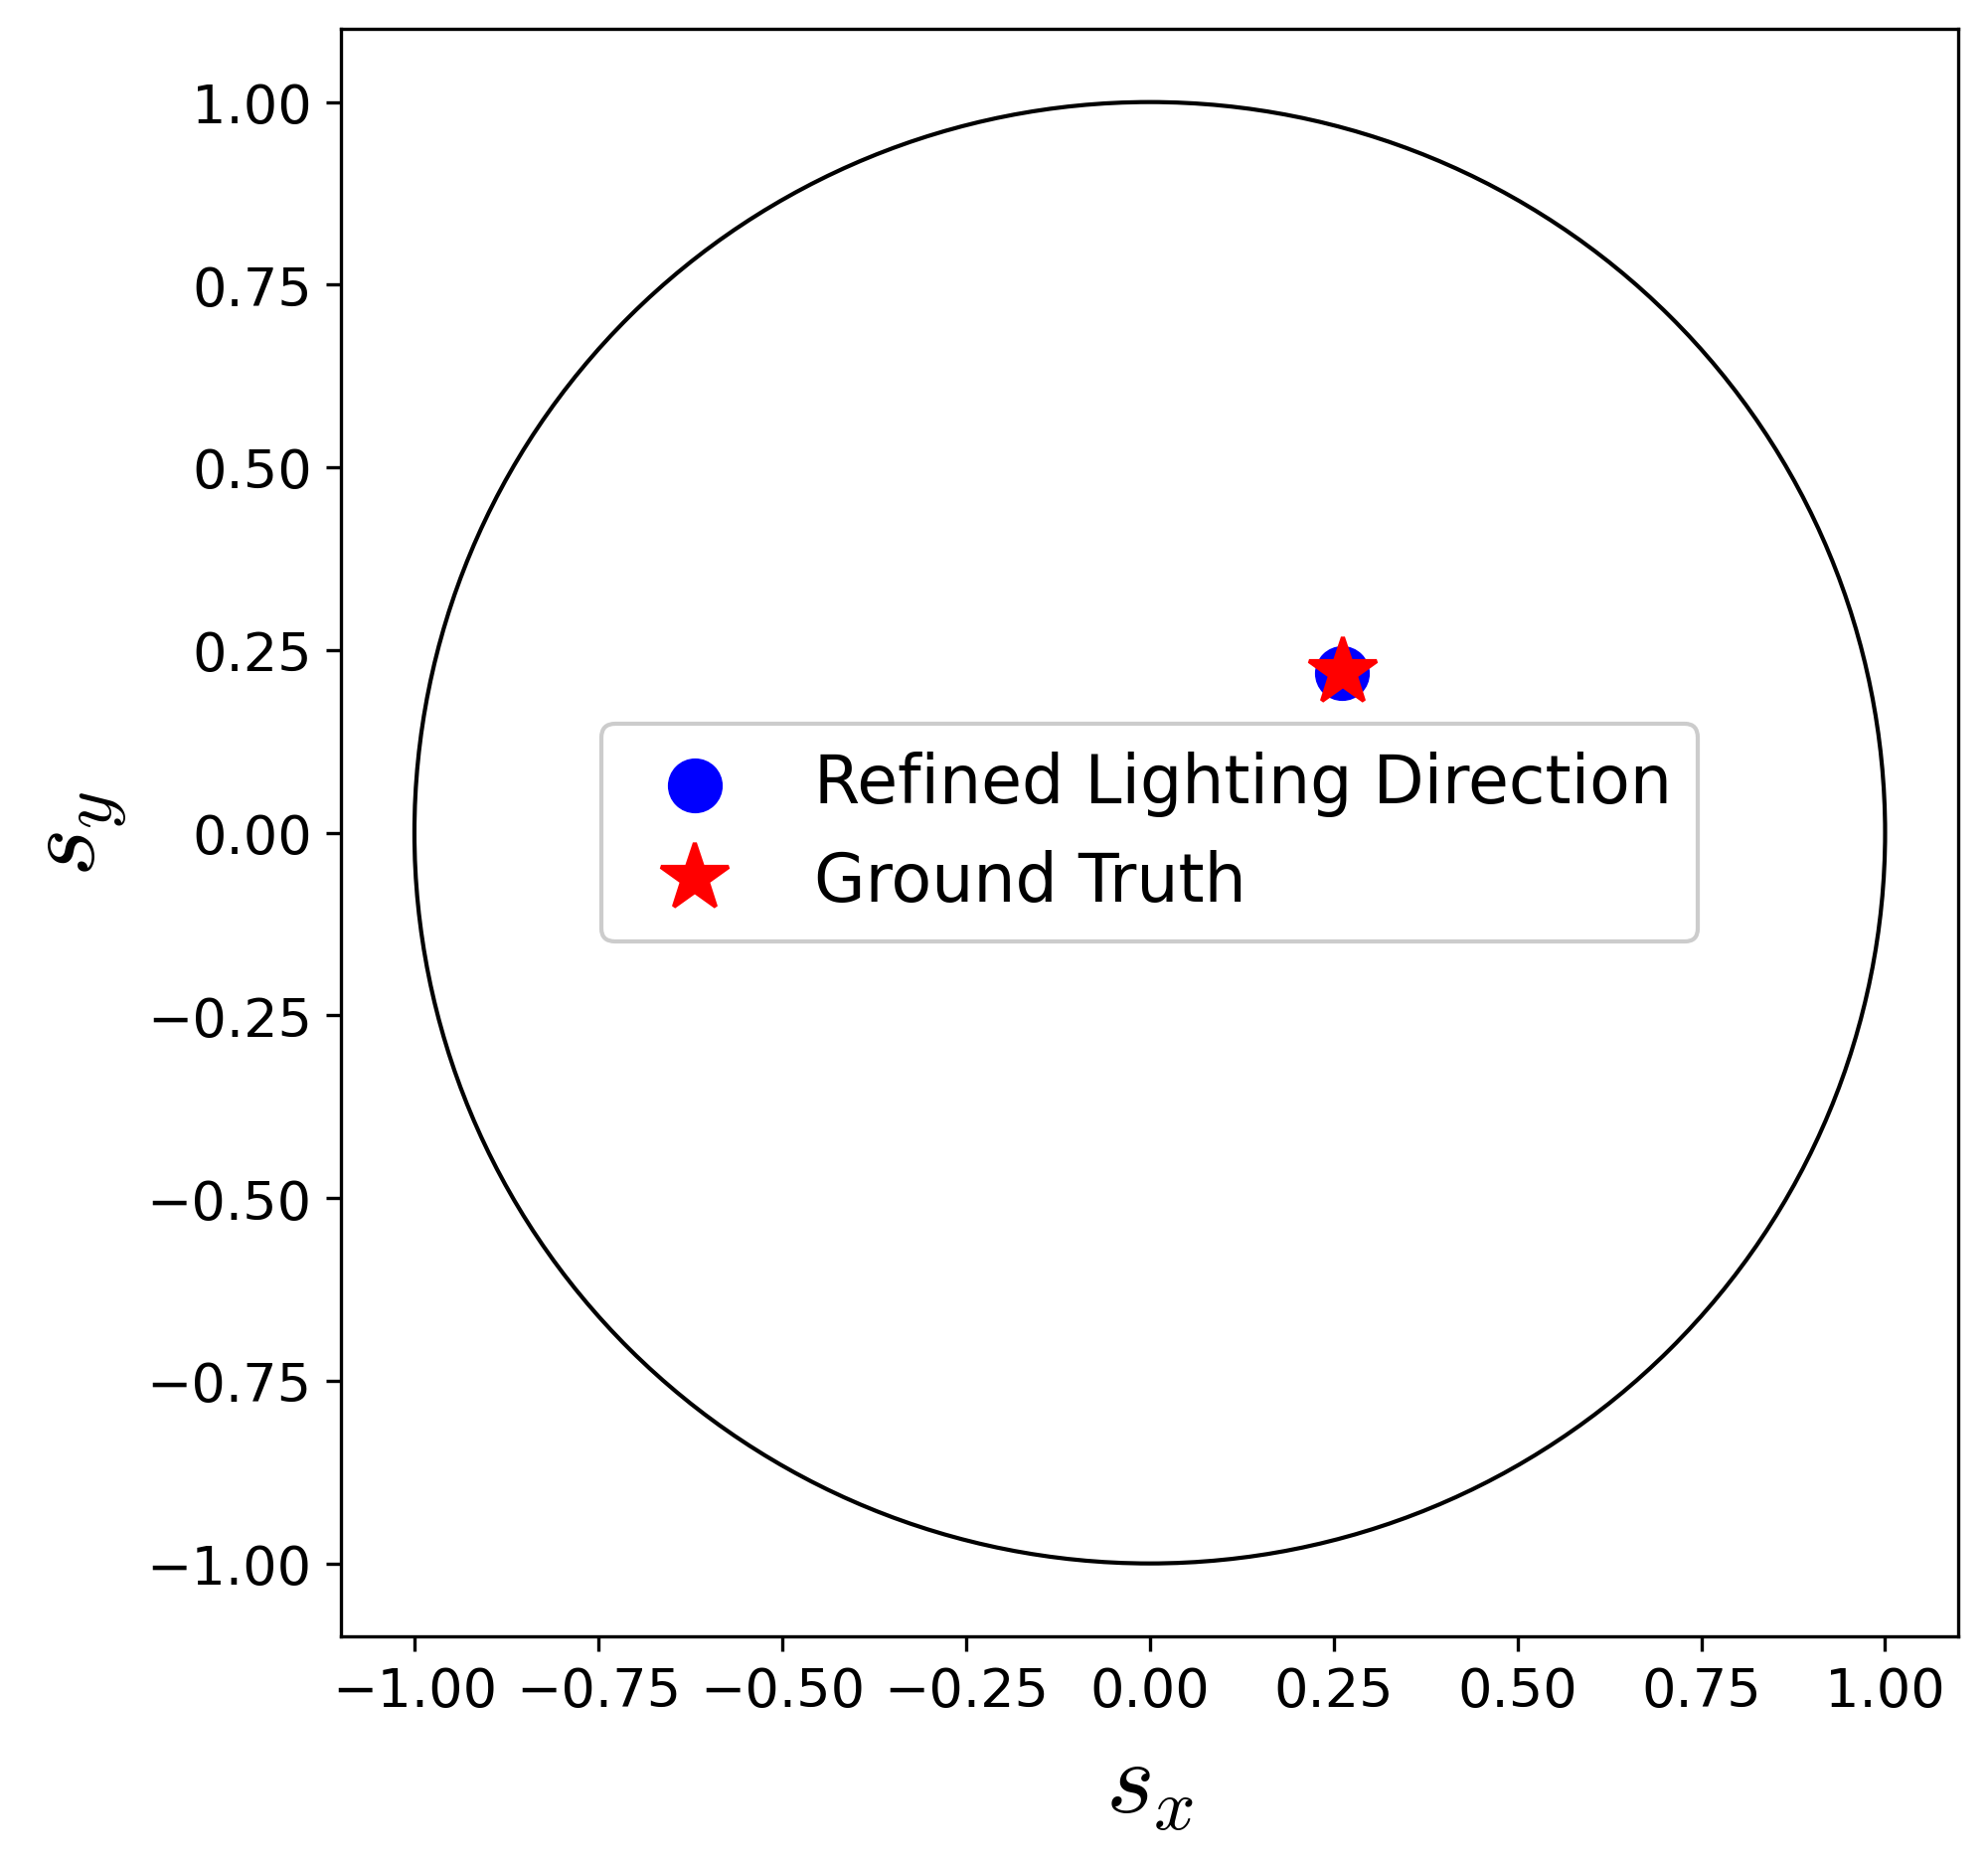

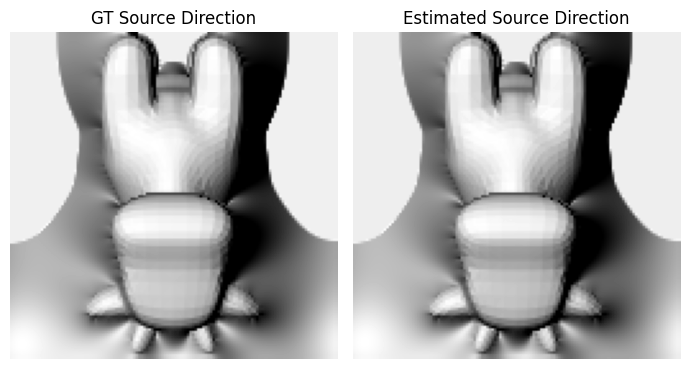

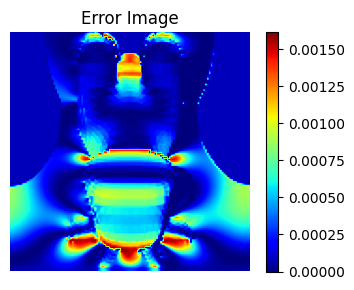

In [23]:
# Convert ground truth and estimated values to unit vectors
sx_gt, sy_gt, sz_gt = pq_to_unit_vector(ps_gt, qs_gt)
sx_est_final, sy_est_final, sz_est_final = pq_to_unit_vector(ps_final, qs_final)

marker_size = 17
scatter_marker_size = 150
plt.figure(figsize=(7,7), dpi=300)
plt.scatter(sx_est_final, sy_est_final, s=scatter_marker_size, color='blue', label='Refined Lighting Direction')
plt.plot(sx_gt, sy_gt, marker='*', markersize=marker_size, color='red', linestyle='None', label='Ground Truth')

circle = plt.Circle((0, 0), 1.0, fill=False, color='black')
plt.gca().add_patch(circle)

plt.xlim([-1.1, 1.1])
plt.ylim([-1.1, 1.1])
plt.xlabel(r"$s_x$", fontsize=25)
plt.ylabel(r"$s_y$", fontsize=25)
plt.xticks(fontsize=13)
plt.yticks(fontsize=13)
#plt.title("Initial Estimated Lighting Direction", fontsize=18)
plt.legend(fontsize=16, framealpha=1.0)
plt.show()

# Shading image
eta_est_1d_est_final = compute_shading_value(p_gt, q_gt, ps_final, ps_final)
eta_est_final = eta_est_1d_est_final.reshape((height, width))
error_image_final = (eta_gt - eta_est_final)**2
#error_image_final = (eta_est - eta_est_final)**2

plt.figure(figsize=(7,5))
plt.subplot(1,2,1)
plt.title("GT Source Direction")
plt.imshow(eta_gt, cmap='gray')
plt.axis("off")
plt.subplot(1,2,2)
plt.title("Estimated Source Direction")
plt.imshow(eta_est_final, cmap='gray')
plt.axis("off")
plt.tight_layout()
plt.show()

plt.figure(figsize=(4,3))
plt.title("Error Image")
plt.imshow(error_image_final, cmap='jet')
plt.axis("off")
plt.colorbar()
plt.tight_layout()
plt.show()

In [24]:
# Compute the angler error
s_gt = np.array([ps_gt, qs_gt, 1.0])
s_est = np.array([ps_est, qs_est, 1.0])

s_gt_norm = s_gt / np.linalg.norm(s_gt)
s_est_norm = s_est / np.linalg.norm(s_est)

dot_product = np.dot(s_gt_norm, s_est_norm)
dot_product = np.clip(dot_product, -1.0, 1.0)

angle_error_rad = np.arccos(dot_product)
angle_error_deg = np.degrees(angle_error_rad)

print(f"Angular error in light source direction: {angle_error_deg:.3f} degrees")

Angular error in light source direction: 1.076 degrees


In [25]:
# Compute the angler error
s_gt = np.array([ps_gt, qs_gt, 1.0])
s_est = np.array([ps_final, qs_final, 1.0])

s_gt_norm = s_gt / np.linalg.norm(s_gt)
s_est_norm = s_est / np.linalg.norm(s_est)

dot_product = np.dot(s_gt_norm, s_est_norm)
dot_product = np.clip(dot_product, -1.0, 1.0)

angle_error_rad = np.arccos(dot_product)
angle_error_deg = np.degrees(angle_error_rad)

print(f"Angular error in light source direction: {angle_error_deg:.3f} degrees")

Angular error in light source direction: 0.066 degrees


In [26]:
print(ps_est, qs_est)
print(ps_final, qs_final)

0.25872206129952885 0.2375143533473558
0.27818828672084256 0.2328210795016188
